In [1]:
%pip install pandas numpy matplotlib seaborn scikit-learn


[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python3 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
# Import core data analysis libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
# Load the exported RFM dataset
df = pd.read_csv('olist_rfm_features.csv')

In [4]:
# Display the first 5 rows to verify the load was successful
df.head()

,customer_unique_id,frequency_total_orders,monetary_total_spent,avg_review_score,is_churned
0,0000366f3b9a7992bf8c76cfdf3221e2,1,141.90,5.0,0
1,0000b849f77a49e4a4ce2b2a4ca5be3f,1,27.19,4.0,0
2,0000f46a3911fa3c0805444483337064,1,86.22,3.0,1
3,0000f6ccb0745a6a4b88665a16c9f078,1,43.62,4.0,1
4,0004aac84e0df4da2b147fca70cf8255,1,196.89,5.0,1


In [5]:
from sklearn.model_selection import train_test_split

In [6]:
# 1. Define Features (X) and Target (y)
# We drop the customer ID because it is a random string, not a pr
X = df.drop(columns=['customer_unique_id', 'is_churned'])
y = df['is_churned']

In [7]:
# 2. Split the data (80% for training, 20% for testing)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [8]:
# 3. Verify the split
print(f"Training features shape: {X_train.shape}")
print(f"Testing features shape: {X_test.shape}")

Training features shape: (74685, 3)
Testing features shape: (18672, 3)


In [9]:
# 4. Calculate the correlation matrix dynamically
available_cols = ['frequency_total_orders', 'monetary_total_spent', 'is_churned']

# Check which version of the dataset you are currently using
if 'recency_days' in df.columns:
    available_cols.insert(0, 'recency_days')
elif 'avg_review_score' in df.columns:
    available_cols.insert(0, 'avg_review_score')

corr_matrix = df[available_cols].corr()

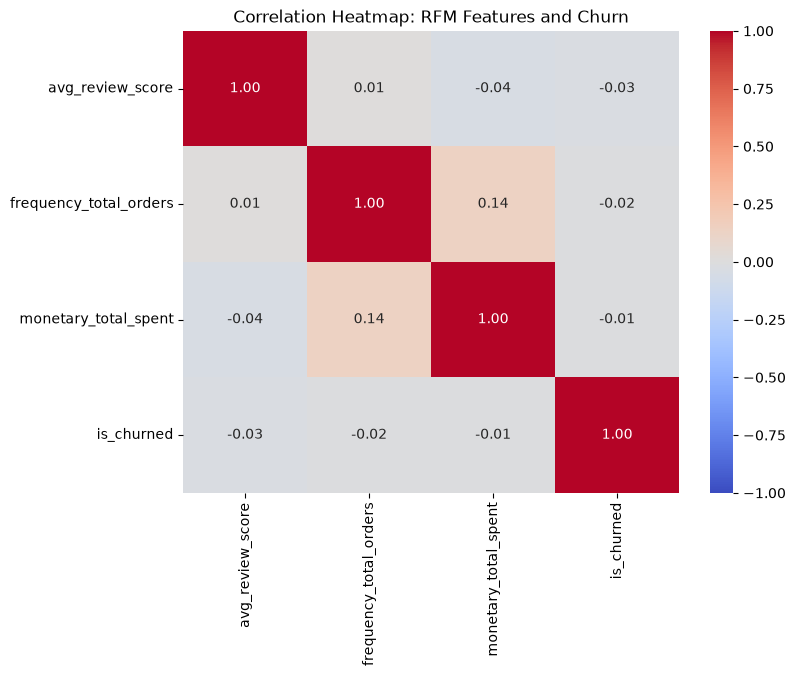

In [10]:
# 5. Generate the heatmap
# Set up the matplotlib figure
plt.figure(figsize=(8, 6))
# Draw the heatmap using seaborn
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1)
# Add a title 
plt.title("Correlation Heatmap: RFM Features and Churn")
plt.show()

In [11]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score


In [12]:
# 1. Initialize the Random Forest model (using 100 decision trees)
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)

In [13]:
# 2. Train (fit) the model on your 74,000+ training rows
rf_model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [14]:
# 3. Ask the trained model to predict churn on the 18,000+ testing hidden
y_pred = rf_model.predict(X_test)

In [15]:
# 4. Grade the model's performance
accuracy = accuracy_score(y_test, y_pred)
print(f"Model Accuracy: {accuracy * 100:.2f}%\n")
print("Detailed Classification Report:")
print(classification_report(y_test, y_pred))

Model Accuracy: 70.25%

Detailed Classification Report:
              precision    recall  f1-score   support

           0       0.64      0.62      0.63      7659
           1       0.74      0.76      0.75     11013

    accuracy                           0.70     18672
   macro avg       0.69      0.69      0.69     18672
weighted avg       0.70      0.70      0.70     18672



In [16]:
# 1. Define features (X) strictly as Frequency and Monetary
# We include 'avg_review_score' in the drop list just in case it is there, 
# and errors='ignore' ensures the code never crashes if a column is missing!
cols_to_drop = ['customer_unique_id', 'is_churned', 'recency_days', 'avg_review_score']

X_strict = df.drop(columns=cols_to_drop, errors='ignore')
y_strict = df['is_churned']


In [17]:
# 2. Split the new data
X_train_S, X_test_S, y_train_S, y_test_S = train_test_split(X_strict, y_strict, test_size=0.2, random_state=42)


In [18]:
# 3. Train a new Random Forest model
rf_model_strict = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model_strict.fit(X_train_S, y_train_S)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [19]:
# 4. Predict and score
y_pred_S = rf_model_strict.predict(X_test_S)
strict_accuracy = accuracy_score(y_test_S, y_pred_S)


print(f"Realistic Model Accuracy (Behavior Only): {strict_accuracy * 100:.2f}%\n")
print(classification_report(y_test_S, y_pred_S))

Realistic Model Accuracy (Behavior Only): 74.26%

              precision    recall  f1-score   support

           0       0.69      0.67      0.68      7659
           1       0.78      0.79      0.78     11013

    accuracy                           0.74     18672
   macro avg       0.73      0.73      0.73     18672
weighted avg       0.74      0.74      0.74     18672



In [20]:
# Load the newly exported dataset that includes 'avg_review_score'
df_upgraded = pd.read_csv('olist_rfm_features.csv')

In [21]:
# 1. Define Features (X) and Target (y)
# Notice we now have 3 behavioral features: frequency, monetary, and avg_review_score
X_upgraded = df_upgraded.drop(columns=['customer_unique_id', 'is_churned'])
y_upgraded = df_upgraded['is_churned']

In [22]:
# 2. Split the data
X_train_up, X_test_up, y_train_up, y_test_up = train_test_split(
    X_upgraded, y_upgraded, test_size=0.2, random_state=42
)

In [23]:
# 3. Train the model on the upgraded dataset
rf_model_upgraded = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model_upgraded.fit(X_train_up, y_train_up)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [24]:
# 4. Predict and score
y_pred_up= rf_model_upgraded.predict(X_test_up)
upgraded_accuracy = accuracy_score(y_test_up, y_pred_up)

print(f"Upgraded Model Accuracy (with Reviews): {upgraded_accuracy * 100:.2f}%\n")
print("Detailed Classification Report:")
print(classification_report(y_test_up, y_pred_up))

Upgraded Model Accuracy (with Reviews): 70.25%

Detailed Classification Report:
              precision    recall  f1-score   support

           0       0.64      0.62      0.63      7659
           1       0.74      0.76      0.75     11013

    accuracy                           0.70     18672
   macro avg       0.69      0.69      0.69     18672
weighted avg       0.70      0.70      0.70     18672



In [25]:
# 1. Install XGBoost if you haven't already (uncomment the line below if you get an error)
%pip install xgboost

from xgboost import XGBClassifier

# 2. We will use the exact same X_train_S / X_test_S / X_test_S variable from your successful 74.80% baseline
# (Frequency and Monetary features only, no Recency)

# 3. Initialize and train the XGBoost model
xgb_model = XGBClassifier(n_estimators=100, learning_rate=0.1, random_state=42)
xgb_model.fit(X_train_S, y_train_S)

# 4. Predict and score
y_pred_xgb = xgb_model.predict(X_test_S)
xgb_accuracy = accuracy_score(y_test_S, y_pred_xgb)

print(f"XGBoost Baseline Accuracy: {xgb_accuracy * 100:.2f}%\n")
print(classification_report(y_test_S, y_pred_xgb))


[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python3 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.
XGBoost Baseline Accuracy: 59.77%

              precision    recall  f1-score   support

           0       0.55      0.10      0.17      7659
           1       0.60      0.94      0.73     11013

    accuracy                           0.60     18672
   macro avg       0.58      0.52      0.45     18672
weighted avg       0.58      0.60      0.50     18672



In [26]:
from sklearn.model_selection import RandomizedSearchCV

# 1. Define the "dials" we want the AI to test
param_grid = {
    'n_estimators': [100, 200, 300],          # Number of trees in the forest
    'max_depth': [None, 10, 20, 30],          # How deep each tree can grow
    'min_samples_split': [2, 5, 10],          # Minimum customers needed to split a node
    'min_samples_leaf': [1, 2, 4]             # Minimum customers allowed in a leaf
}

# 2. Initialize a blank Random Forest
rf_base = RandomForestClassifier(random_state=42)

# 3. Set up the Randomized Search
# n_iter=10 means it will test 10 different combinations
# cv=3 means it will cross-validate 3 times to ensure the results aren't a fluke
# n_jobs=-1 tells Python to use ALL of your Mac's CPU cores to speed it up!
rf_random = RandomizedSearchCV(
    estimator=rf_base, 
    param_distributions=param_grid, 
    n_iter=10, 
    cv=3, 
    verbose=2, 
    random_state=42, 
    n_jobs=-1 
)

# 4. Start the tuning process on our strict behavioral data
print("Starting hyperparameter tuning... this might take a minute or two!")
rf_random.fit(X_train_S, y_train_S)

# 5. Extract the best model and test it
best_rf_model = rf_random.best_estimator_
y_pred_best = best_rf_model.predict(X_test_S)
best_accuracy = accuracy_score(y_test_S, y_pred_best)

print(f"\nBest Hyperparameters found: {rf_random.best_params_}")
print(f"Tuned Random Forest Accuracy: {best_accuracy * 100:.2f}%\n")
print(classification_report(y_test_S, y_pred_best))


Starting hyperparameter tuning... this might take a minute or two!
Fitting 3 folds for each of 10 candidates, totalling 30 fits
[CV] END max_depth=None, min_samples_leaf=1, min_samples_split=5, n_estimators=200; total time=  30.4s
[CV] END max_depth=20, min_samples_leaf=4, min_samples_split=5, n_estimators=300; total time=  30.9s
[CV] END max_depth=None, min_samples_leaf=2, min_samples_split=2, n_estimators=200; total time=  30.9s
[CV] END max_depth=20, min_samples_leaf=4, min_samples_split=5, n_estimators=300; total time=  31.7s
[CV] END max_depth=None, min_samples_leaf=1, min_samples_split=5, n_estimators=200; total time=  31.8s
[CV] END max_depth=None, min_samples_leaf=2, min_samples_split=2, n_estimators=200; total time=  31.9s
[CV] END max_depth=20, min_samples_leaf=4, min_samples_split=5, n_estimators=300; total time=  32.3s
[CV] END max_depth=None, min_samples_leaf=2, min_samples_split=2, n_estimators=200; total time=  32.8s
[CV] END max_depth=20, min_samples_leaf=2, min_samples

In [27]:
# Extract the importance scores from your tuned model
importances = best_rf_model.feature_importances_

In [28]:
# Map the score to your feature names
feature_names = X_train_S.columns
fi_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})
fi_df = fi_df.sort_values(by='Importance', ascending=False)



/var/folders/_9/sg4x9bzs6ms8zmxg14mb8xqm0000gn/T/ipykernel_10816/3325447430.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=fi_df, palette='mako')


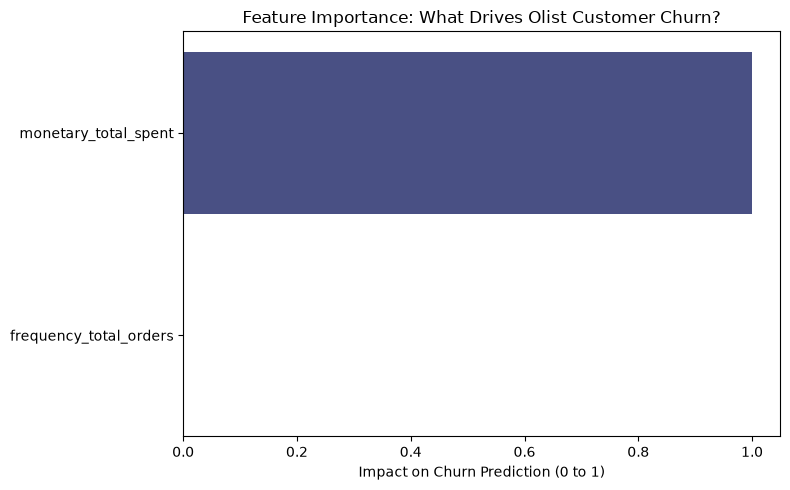

In [29]:
# Build a clean, professional bar chart
plt.figure(figsize=(8, 5))
sns.barplot(x='Importance', y='Feature', data=fi_df, palette='mako')
plt.title('Feature Importance: What Drives Olist Customer Churn?')
plt.xlabel('Impact on Churn Prediction (0 to 1)')
plt.ylabel('')
plt.tight_layout()
plt.show()

In [30]:
# 1. Create a copy of your test data so we can compare actuals vs. predictions
results_df = X_test_S.copy()
results_df['Actual_Churn'] = y_test_S
results_df['Predicted_Churn'] = y_pred_best

# 2. Filter for True Positives (Actual = 1 AND Predicted = 1)
true_positives = results_df[(results_df['Actual_Churn'] == 1) & (results_df['Predicted_Churn'] == 1)]

# 3. Sum the monetary value of these correctly identified at-risk customers
at_risk_revenue = true_positives['monetary_total_spent'].sum()

# 4. Print the final business metrics
print(f"Total At-Risk Customers Identified: {len(true_positives):,}")
print(f"Total Revenue Successfully Flagged: ${at_risk_revenue:,.2f}")


Total At-Risk Customers Identified: 8,763
Total Revenue Successfully Flagged: $1,321,895.81
